# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [1]:
import sys
import requests
from bs4 import BeautifulSoup

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

def parse_web_page(url):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    response = requests.get(url, headers=headers, timeout=15)
    response.raise_for_status()
    response.encoding = response.apparent_encoding or "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")
    for element in soup(["script", "style", "noscript"]):
        element.decompose()
    return soup.get_text(separator=" ", strip=True)

print(parse_web_page('https://fmi.chnu.edu.ua/')[:255])
print(parse_web_page('https://en.wikipedia.org/wiki/Web_scraping')[:255])


Головна - Факультет математики та інформатики Перейти до основного вмісту clg-math@chnu.edu.ua 58012, Україна, м. Чернівці, вул. Університетська, 28 Новини Всі Загальні Оголошення Події Студенту Викладачу Вітання Діяльність Наукова Конференції Семінари Ас


Web scraping - Wikipedia Jump to content Main menu Main menu move to sidebar hide Navigation Main page Contents Current events Random article About Wikipedia Contact us Contribute Help Learn to edit Community portal Recent changes Upload file Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [2]:
import json
import requests

def parse_api(api_url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(api_url, headers=headers, timeout=15)
    response.raise_for_status()
    data = response.json()
    with open("result.json", "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4, ensure_ascii=False)

parse_api('https://api.github.com/')


## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [3]:
import json
import os
from datetime import datetime

def parse_json(date):
    path = "resources/weather.json" if os.path.exists("resources/weather.json") else "weather.json"
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    
    parsed_target = datetime.strptime(date, "%Y-%m-%d").date()
    for item in data.get("daily", []):
        if datetime.strptime(item.get("date"), "%Y-%m-%d").date() == parsed_target:
            return list(item.values())
    return []

target_date = '2024-8-19'
print(parse_json(target_date))


['2024-08-19', 30.0, 21.0, 5.0, 10.0, 70, 'Light rain']


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [4]:
import csv
import os
from datetime import datetime

def parse_csv(date):
    path = "resources/weather.csv" if os.path.exists("resources/weather.csv") else "weather.csv"
    parsed_target = datetime.strptime(date, "%Y-%m-%d").date()
    with open(path, mode="r", encoding="utf-8") as f:
        reader = csv.reader(f)
        next(reader)
        for row in reader:
            if not row or not row[0]:
                continue
            try:
                row_date = datetime.strptime(row[0].strip(), "%Y-%m-%d").date()
                if row_date == parsed_target:
                    return row
            except ValueError:
                continue
    return []

target_date = '1997-5-22'
print(parse_csv(target_date))


['1997-5-22', '25', '18', '10', '11', '8', '6', '88', '54', '34', '1017', '1015', '1012', '10', '10', '10', '11', '3', '', '0.00', '3', '', '277']


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

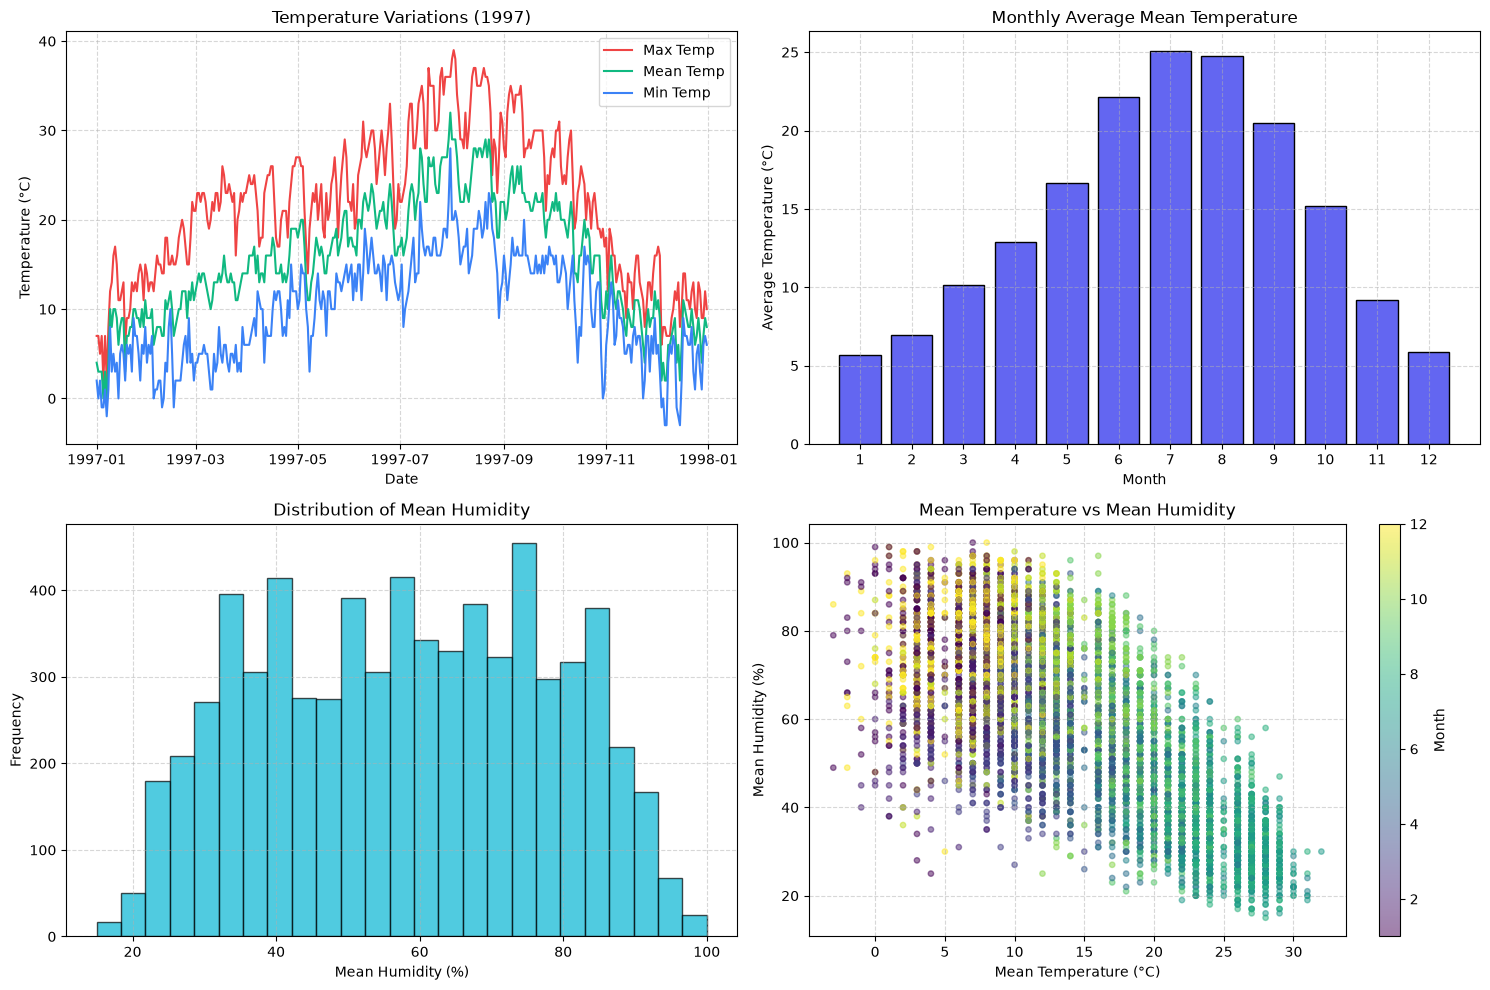

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def visualize_data():
    path = "resources/weather.csv" if os.path.exists("resources/weather.csv") else "weather.csv"
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    df["CET"] = pd.to_datetime(df["CET"])
    df["Max TemperatureC"] = pd.to_numeric(df["Max TemperatureC"], errors="coerce")
    df["Mean TemperatureC"] = pd.to_numeric(df["Mean TemperatureC"], errors="coerce")
    df["Min TemperatureC"] = pd.to_numeric(df["Min TemperatureC"], errors="coerce")
    df["Mean Humidity"] = pd.to_numeric(df["Mean Humidity"], errors="coerce")
    df["Precipitationmm"] = pd.to_numeric(df["Precipitationmm"], errors="coerce")
    df["WindDirDegrees"] = pd.to_numeric(df["WindDirDegrees"], errors="coerce")

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    df_sample = df[df["CET"].dt.year == 1997]
    axes[0, 0].plot(df_sample["CET"], df_sample["Max TemperatureC"], color="#ef4444", label="Max Temp")
    axes[0, 0].plot(df_sample["CET"], df_sample["Mean TemperatureC"], color="#10b981", label="Mean Temp")
    axes[0, 0].plot(df_sample["CET"], df_sample["Min TemperatureC"], color="#3b82f6", label="Min Temp")
    axes[0, 0].set_title("Temperature Variations (1997)")
    axes[0, 0].set_xlabel("Date")
    axes[0, 0].set_ylabel("Temperature (°C)")
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle="--", alpha=0.5)

    df["Month"] = df["CET"].dt.month
    monthly_temp = df.groupby("Month")["Mean TemperatureC"].mean()
    axes[0, 1].bar(monthly_temp.index, monthly_temp.values, color="#6366f1", edgecolor="black")
    axes[0, 1].set_title("Monthly Average Mean Temperature")
    axes[0, 1].set_xlabel("Month")
    axes[0, 1].set_ylabel("Average Temperature (°C)")
    axes[0, 1].set_xticks(range(1, 13))
    axes[0, 1].grid(True, linestyle="--", alpha=0.5)

    axes[1, 0].hist(df["Mean Humidity"].dropna(), bins=25, color="#06b6d4", edgecolor="black", alpha=0.7)
    axes[1, 0].set_title("Distribution of Mean Humidity")
    axes[1, 0].set_xlabel("Mean Humidity (%)")
    axes[1, 0].set_ylabel("Frequency")
    axes[1, 0].grid(True, linestyle="--", alpha=0.5)

    scatter = axes[1, 1].scatter(df["Mean TemperatureC"], df["Mean Humidity"], c=df["Month"], cmap="viridis", alpha=0.5, s=15)
    axes[1, 1].set_title("Mean Temperature vs Mean Humidity")
    axes[1, 1].set_xlabel("Mean Temperature (°C)")
    axes[1, 1].set_ylabel("Mean Humidity (%)")
    cbar = fig.colorbar(scatter, ax=axes[1, 1])
    cbar.set_label("Month")
    axes[1, 1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig("weather_visualization.png", dpi=300)
    plt.show()

visualize_data()


## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

C:\Users\Віктор\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


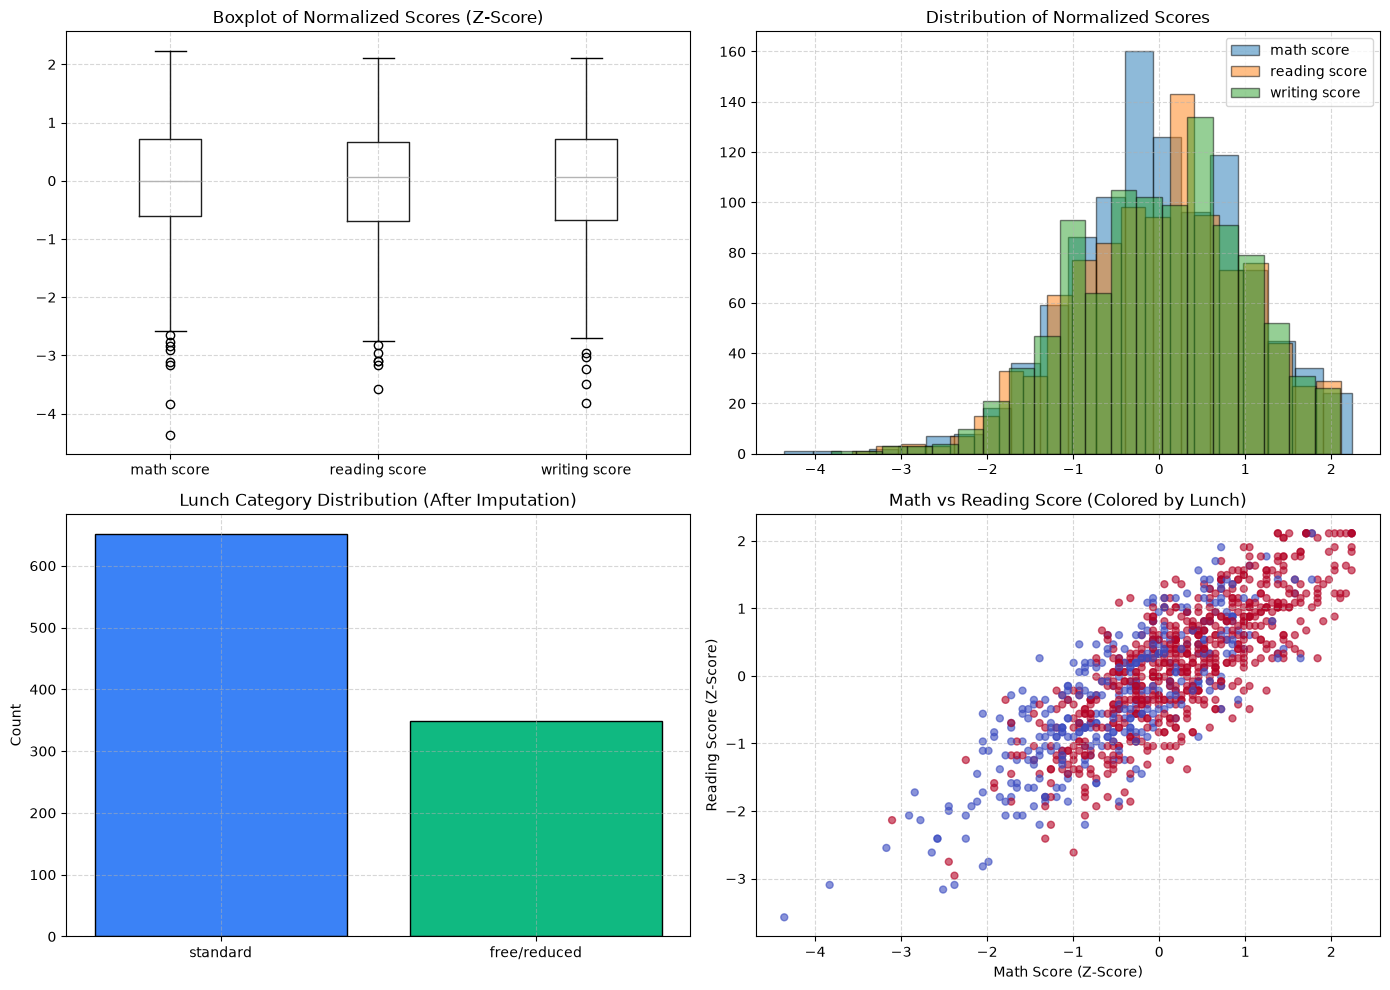

In [6]:
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def load_dataset(url, csv_file):
    try:
        return kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    except Exception:
        path = kagglehub.dataset_download(url)
        return pd.read_csv(os.path.join(path, csv_file))

def impute_data(df):
    df_imputed = df.copy()
    num_cols = list(df_imputed.select_dtypes(include=[np.number]).columns)
    cat_cols = list(df_imputed.select_dtypes(exclude=[np.number]).columns)

    for col in num_cols:
        if df_imputed[col].isnull().sum() > 0:
            df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())

    for col in cat_cols:
        if df_imputed[col].isnull().sum() > 0:
            if col == "lunch" and len(num_cols) > 0:
                std_scores = (df_imputed[num_cols] - df_imputed[num_cols].mean()) / df_imputed[num_cols].std()
                known = df_imputed[df_imputed[col].notnull()]
                missing = df_imputed[df_imputed[col].isnull()]
                known_feats = std_scores.loc[known.index].values
                missing_feats = std_scores.loc[missing.index].values
                known_labels = (known[col] == "standard").astype(int).values
                imputed_labels = []
                for m in missing_feats:
                    dists = np.linalg.norm(known_feats - m, axis=1)
                    k_nn = known_labels[np.argsort(dists)[:5]]
                    imputed_labels.append("standard" if np.mean(k_nn) >= 0.5 else "free/reduced")
                df_imputed.loc[missing.index, col] = imputed_labels
            else:
                df_imputed[col] = df_imputed[col].fillna(df_imputed[col].mode()[0])

    return df_imputed

def normalize_data(df):
    df_normalized = df.copy()
    num_cols = df_normalized.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        col_std = df_normalized[col].std()
        df_normalized[col] = (df_normalized[col] - df_normalized[col].mean()) / (col_std if col_std != 0 else 1.0)
    return df_normalized

def visualize_data(df):
    num_cols = list(df.select_dtypes(include=[np.number]).columns)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    df[num_cols].boxplot(ax=axes[0, 0])
    axes[0, 0].set_title("Boxplot of Normalized Scores (Z-Score)")
    axes[0, 0].grid(True, linestyle="--", alpha=0.5)

    for col in num_cols:
        axes[0, 1].hist(df[col], bins=20, alpha=0.5, label=col, edgecolor="black")
    axes[0, 1].set_title("Distribution of Normalized Scores")
    axes[0, 1].legend()
    axes[0, 1].grid(True, linestyle="--", alpha=0.5)

    lunch_counts = df["lunch"].value_counts()
    axes[1, 0].bar(lunch_counts.index, lunch_counts.values, color=["#3b82f6", "#10b981"], edgecolor="black")
    axes[1, 0].set_title("Lunch Category Distribution (After Imputation)")
    axes[1, 0].set_ylabel("Count")
    axes[1, 0].grid(True, linestyle="--", alpha=0.5)

    scatter = axes[1, 1].scatter(
        df["math score"],
        df["reading score"],
        c=(df["lunch"] == "standard").astype(int),
        cmap="coolwarm",
        alpha=0.6,
        s=25
    )
    axes[1, 1].set_title("Math vs Reading Score (Colored by Lunch)")
    axes[1, 1].set_xlabel("Math Score (Z-Score)")
    axes[1, 1].set_ylabel("Reading Score (Z-Score)")
    axes[1, 1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig("students_visualization.png", dpi=300)
    plt.show()

df = load_dataset('ilayaraja07/data-cleaning-feature-imputation', 'Students_Performance_knn.csv')
df = impute_data(df)
df = normalize_data(df)
visualize_data(df)
